# Why Do Online Learners Drop Out?

### A retention analysis of 32,593 enrolments (28,785 students) on the Open University’s online learning platform

In this notebook we'll explore the [Open University Learning Analytics Dataset (OULAD)](https://analyse.kmi.open.ac.uk/open_dataset), which covers 22 module presentations from 2013–2014: student demographics, assessment results, and about 10.6 million daily summaries of clicks in the university's online learning environment.

Imagine we're working with an edtech platform's retention team. They want to know which students are likely to withdraw, and how early the warning signs show up. If we think of students as customers, withdrawal is churn and clicks are product engagement.

We'll try to answer the following questions:

- Who are the students?
- What happens to them by the end of the course?
- When do students withdraw, and is the pattern the same for February and October starts?
- Does early engagement tell us who will leave?
- Which learning activities matter most?
- Does background raise the risk of withdrawing?
- Does the first assessment predict the final result?
- Can we flag at-risk students by the end of week 4?
- Do simple alert rules work, and how do they compare with the model?

> **Key findings**
>
> - **31.2% of enrolments ended in withdrawal**, and about half of those happened by day 27 (50%, or 46% excluding a one-day spike in October 2014): 26.3% before the module even started. No week-4 alert can reach them.
> - **Early engagement separates passing from not passing, but not withdrawal from failure.** Among students still registered on day 27, those who later withdrew had a median of 143 clicks in the first four weeks vs 217 for those with a Pass, but students who stayed and failed were even less active (103).
> - **Missing the first-assessment deadline gives the highest lift at equal outreach volume, and the widest reach.** Where it's due by day 25 (2014 data), it flags 39% of students, 32.5% of whom go on to withdraw (1.47× the baseline). On the 12,509 students the week-4 model can also score, the alert's lift is 1.44× against 1.24× for the model flagging the same share (gap +0.20, 95% bootstrap interval +0.13 to +0.26, covering sampling noise in the 2014 students only). The other 158 students all withdrew before the model could score them, and the alert had already flagged 145. It catches a quarter of all 2014 withdrawals, up to two weeks before week 4. Students who never submit are the highest risk: only 4.8% pass.
> - **A week-4 model works better for "not passing" than for withdrawal alone**: ROC AUC 0.713 vs 0.614, and 70.5% of the riskiest 20% didn't pass (43.7% baseline). Neither model is strong, so they're best used to prioritise outreach.
> - **Workload is the biggest background risk**: withdrawal doubles from 25.4% for students taking 60 credits or fewer to 51.3% for those taking over 120.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)

DATA_DIR = Path('data/raw')    # unzip the OULAD CSV files here
FIG_DIR = Path('figures')      # charts are saved here for the README
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name):
    """Save a figure to figures/ so it can be used in the README."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


# A student on a module presentation is identified by these three columns
KEYS = ['code_module', 'code_presentation', 'id_student']

OUTCOME_ORDER = ['Distinction', 'Pass', 'Fail', 'Withdrawn']
OUTCOME_COLORS = {'Distinction': '#1b7837', 'Pass': '#7fbf7b',
                  'Fail': '#f4a582', 'Withdrawn': '#b2182b'}

## 1. Loading the data

The dataset comes as seven CSV files, linked by the module code, the presentation code and the student id. Missing values are stored as `?`, so we tell pandas to read those as empty.

In [2]:
def read(name, **kwargs):
    return pd.read_csv(DATA_DIR / f'{name}.csv', na_values='?', **kwargs)


courses = read('courses')
assessments = read('assessments')
vle = read('vle')
student_info = read('studentInfo')
registration = read('studentRegistration')
student_assessment = read('studentAssessment')

for name, df in [('courses', courses), ('assessments', assessments), ('vle', vle),
                 ('studentInfo', student_info), ('studentRegistration', registration),
                 ('studentAssessment', student_assessment)]:
    print(f'{name:<20} {len(df):>9,} rows  {df.shape[1]:>2} columns')

courses                     22 rows   3 columns
assessments                206 rows   6 columns
vle                      6,364 rows   6 columns
studentInfo             32,593 rows  12 columns
studentRegistration     32,593 rows   5 columns
studentAssessment      173,912 rows   5 columns


The click log, `studentVle`, is the big one: about 10.6 million rows. We'll load it with compact data types, then immediately summarise it into the three views we need:

- clicks per student per **week**
- clicks and active days in the **first four weeks** (days 0–27)
- clicks per student per **learning resource** in the first four weeks (to compare activity types fairly later)

After that we can drop the raw log to free up memory.

In [3]:
student_vle = read('studentVle', dtype={'code_module': 'category', 'code_presentation': 'category',
                                        'id_student': 'int32', 'id_site': 'int32',
                                        'date': 'int16', 'sum_click': 'int32'})
print(f'{len(student_vle):,} daily click records')

# Week 0 = days 0-6 of the module; negative weeks are before the module starts
student_vle['week'] = (student_vle['date'] // 7).astype('int16')
first_four_weeks = student_vle[student_vle['date'].between(0, 27)]


def summarise(df, by, **aggs):
    out = df.groupby(by, observed=True).agg(**aggs).reset_index()
    return out.astype({'code_module': str, 'code_presentation': str})


weekly_clicks = summarise(student_vle, KEYS + ['week'], clicks=('sum_click', 'sum'))
early_activity = summarise(first_four_weeks, KEYS,
                           early_clicks=('sum_click', 'sum'),
                           early_active_days=('date', 'nunique'))
early_site_clicks = summarise(first_four_weeks, KEYS + ['id_site'], clicks=('sum_click', 'sum'))

del student_vle, first_four_weeks
print(f'Weekly summary: {len(weekly_clicks):,} rows | first-four-weeks summary: {len(early_activity):,} students')

10,655,280 daily click records


Weekly summary: 627,031 rows | first-four-weeks summary: 27,886 students


Let's take a look at the main student table.

In [4]:
student_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   code_module           32593 non-null  str  
 1   code_presentation     32593 non-null  str  
 2   id_student            32593 non-null  int64
 3   gender                32593 non-null  str  
 4   region                32593 non-null  str  
 5   highest_education     32593 non-null  str  
 6   imd_band              31482 non-null  str  
 7   age_band              32593 non-null  str  
 8   num_of_prev_attempts  32593 non-null  int64
 9   studied_credits       32593 non-null  int64
 10  disability            32593 non-null  str  
 11  final_result          32593 non-null  str  
dtypes: int64(3), str(9)
memory usage: 3.0 MB


In [5]:
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


Only `imd_band` has missing values: 1,111 of 32,593 enrolments (3.4%). Rather than guess them, we’ll keep them as a separate “Unknown” band. Everything else is complete. One early signal: only 27,886 enrolments (86%) show any clicks in the first four weeks, so about 4,700 have no activity at all in that period. Some of these students withdrew before the module began; we’ll separate them out later.

A few fixes and additions before we start:

- The `imd_band` column (Index of Multiple Deprivation, where 0–10% is the most deprived) labels one band as `10-20` instead of `10-20%`, so we'll standardise it. Missing values become their own **Unknown** category rather than being guessed, because we have no fair way to fill them.
- We'll set a sensible order for the banded columns so charts read left to right.
- We'll add a `withdrawn` flag (1 = withdrew), the presentation type (February **B** or October **J**) and the year.

Then we join registration dates and the first-four-weeks activity onto one student-level table. Students with no clicks in the first four weeks get 0.

In [6]:
student_info['imd_band'] = student_info['imd_band'].replace({'10-20': '10-20%'}).fillna('Unknown')

imd_order = ['0-10%', '10-20%', '20-30%', '30-40%', '40-50%',
             '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', 'Unknown']
age_order = ['0-35', '35-55', '55<=']
edu_order = ['No Formal quals', 'Lower Than A Level', 'A Level or Equivalent',
             'HE Qualification', 'Post Graduate Qualification']

student_info['withdrawn'] = (student_info['final_result'] == 'Withdrawn').astype(int)
student_info['presentation_type'] = (student_info['code_presentation'].str[-1]
                                     .map({'B': 'February (B)', 'J': 'October (J)'}))
student_info['year'] = student_info['code_presentation'].str[:4].astype(int)

students = (student_info
            .merge(registration, on=KEYS, how='left')
            .merge(early_activity, on=KEYS, how='left')
            .fillna({'early_clicks': 0, 'early_active_days': 0}))

no_date = ((students['withdrawn'] == 1) & students['date_unregistration'].isna()).sum()
print(f"{len(students):,} enrolments from {students['id_student'].nunique():,} unique students")
print(f'{no_date:,} withdrawals have no recorded withdrawal date')

32,593 enrolments from 28,785 unique students
93 withdrawals have no recorded withdrawal date


Each row is one student on one module presentation, so a student taking two modules appears twice. We'll call each row an **enrolment**. The 32,593 enrolments come from 28,785 unique students, so about 3,800 enrolments belong to students taking more than one module or repeating one. Only 93 withdrawals have no recorded date, so leaving them out of time-based comparisons makes little difference.

Several later sections compare students **at a point in time**, so we need a helper that tells us who was still registered on a given day. Withdrawn students with no recorded withdrawal date are left out of these comparisons, because we can't tell when they left.

In [7]:
def registered_on(df, day):
    """True for enrolments still registered at the end of the given day of the module."""
    date_known = ~((df['withdrawn'] == 1) & df['date_unregistration'].isna())
    return date_known & (df['date_unregistration'].isna() | (df['date_unregistration'] > day))


print(f'Still registered at the end of day 27 (week 4): {registered_on(students, 27).sum():,} enrolments')

Still registered at the end of day 27 (week 4): 27,460 enrolments


## 2. Who are the students?

Let's start with some demographics in one grid: age, education level on entry, deprivation band and gender.

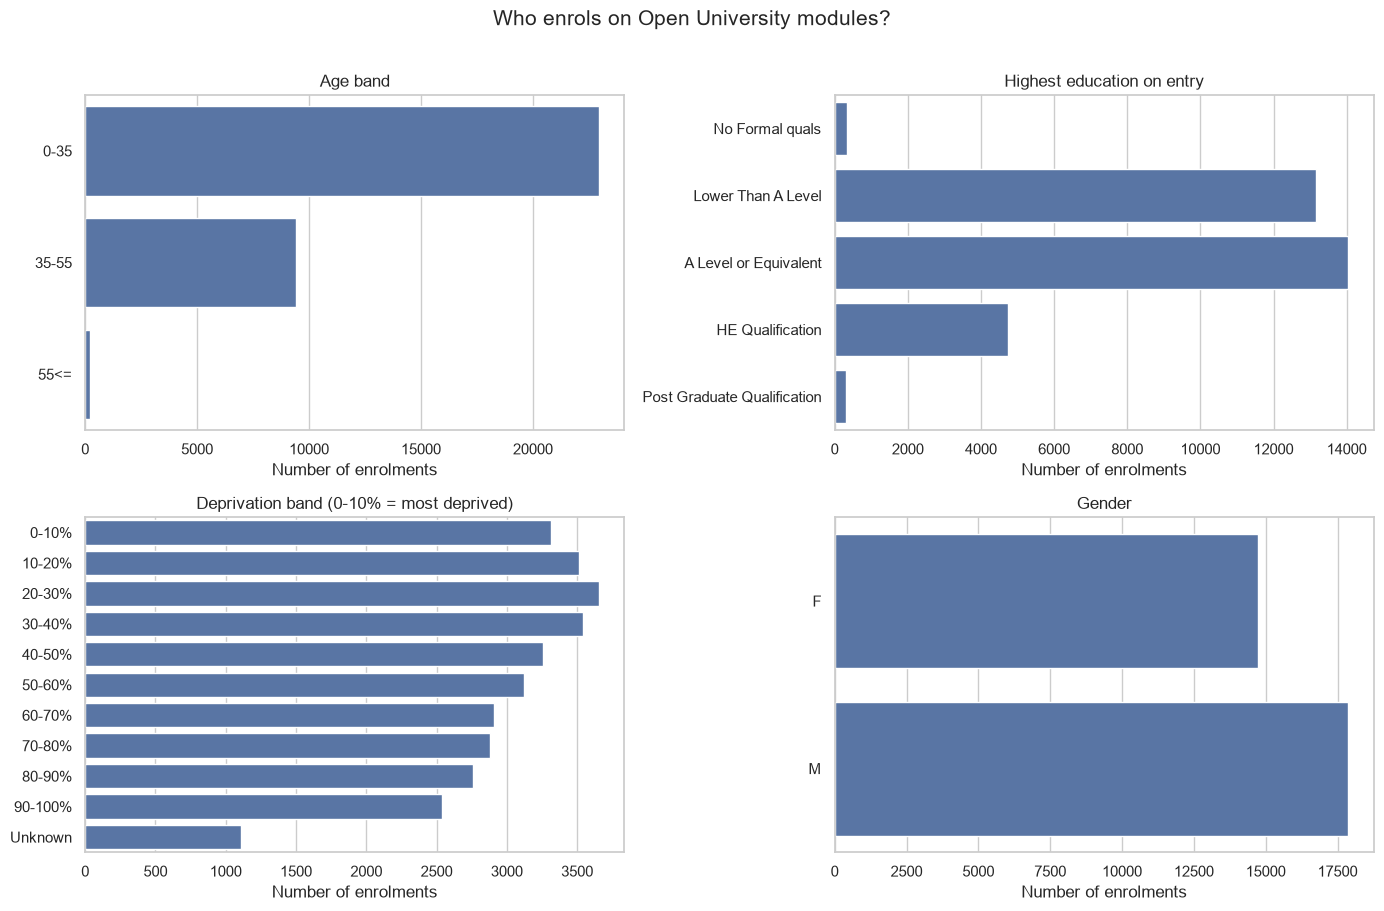

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [('age_band', age_order, 'Age band'),
          ('highest_education', edu_order, 'Highest education on entry'),
          ('imd_band', imd_order, 'Deprivation band (0-10% = most deprived)'),
          ('gender', ['F', 'M'], 'Gender')]

for ax, (col, order, title) in zip(axes.flat, panels):
    sns.countplot(data=students, y=col, order=order, color='#4c72b0', ax=ax)
    ax.set(title=title, xlabel='Number of enrolments', ylabel='')

fig.suptitle('Who enrols on Open University modules?', fontsize=15, y=1.01)
fig.tight_layout()
save(fig, 'demographics')
plt.show()

In [9]:
# Source for the percentages quoted below
for col in ['age_band', 'highest_education', 'gender']:
    print((students[col].value_counts(normalize=True) * 100).round(1).to_string(), '\n')

imd_share = students['imd_band'].value_counts(normalize=True) * 100
most = imd_share[['0-10%', '10-20%', '20-30%', '30-40%']].sum()
least = imd_share[['60-70%', '70-80%', '80-90%', '90-100%']].sum()
print(f"Four most deprived bands: {most:.1f}% | four least deprived: {least:.1f}% | "
      f"Unknown: {imd_share['Unknown']:.1f}%")

age_band
0-35     70.4
35-55    28.9
55<=      0.7 

highest_education
A Level or Equivalent          43.1
Lower Than A Level             40.4
HE Qualification               14.5
No Formal quals                 1.1
Post Graduate Qualification     1.0 

gender
M    54.8
F    45.2 

Four most deprived bands: 43.0% | four least deprived: 34.0% | Unknown: 3.4%


The typical student is under 35 (70.4%) and arrived with A levels or less (83.5%: 43.1% A level or equivalent, 40.4% lower than A level). Students aged 55+ (0.7%), those with no formal qualifications (1.1%) and those with a postgraduate degree (1.0%) are very small groups, so we won’t draw conclusions about them on their own. Enrolments lean towards more deprived areas: the four most deprived bands hold 43.0% of enrolments against 34.0% for the four least deprived, with 3.4% Unknown. Men make up 54.8% of enrolments.

## 3. What happens to students by the end of the course?

`final_result` has four values: Distinction, Pass, Fail and Withdrawn. We'll keep **Fail** and **Withdrawn** separate throughout. They mean different things for the business: a withdrawal is a **retention** problem (the student leaves), while a fail is a **support** problem (the student stays to the end but doesn't pass).

In [10]:
overall = students['final_result'].value_counts(normalize=True).reindex(OUTCOME_ORDER) * 100
overall.round(1).to_frame('% of enrolments')

,% of enrolments
final_result,
Distinction,9.3
Pass,37.9
Fail,21.6
Withdrawn,31.2


And now the same split for each module, sorted by withdrawal rate.

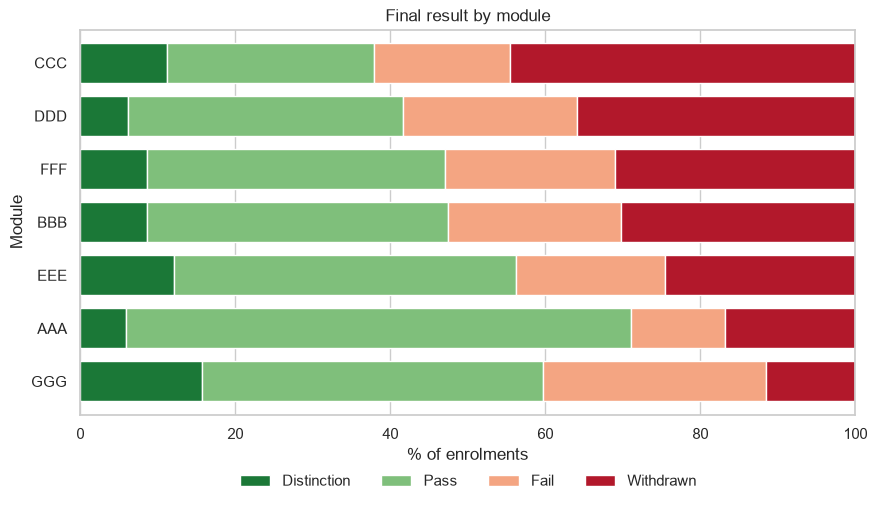

In [11]:
by_module = (pd.crosstab(students['code_module'], students['final_result'], normalize='index')
             .reindex(columns=OUTCOME_ORDER).fillna(0) * 100)
by_module = by_module.sort_values('Withdrawn')

fig, ax = plt.subplots(figsize=(10, 5))
by_module.plot(kind='barh', stacked=True, width=0.75, ax=ax,
               color=[OUTCOME_COLORS[c] for c in OUTCOME_ORDER])
ax.set(title='Final result by module', xlabel='% of enrolments', ylabel='Module', xlim=(0, 100))
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12), frameon=False)
save(fig, 'outcome_by_module')
plt.show()

Fewer than half of enrolments end in a pass (47.2%: 9.3% Distinction, 37.9% Pass). Withdrawal is the biggest non-pass outcome at 31.2%, ahead of failure at 21.6%. Withdrawal also varies far more between modules than failure does: it ranges almost fourfold, from 11.5% in GGG to 44.5% in CCC, while failure stays between 17.6% and 22.5% in five of the seven modules. GGG shows why we keep the two apart: it has the lowest withdrawal rate but the highest fail rate (28.7%), so its students mostly stay but struggle, which is a support problem rather than a retention problem. AAA does best overall, with 71.0% passing and only 16.8% withdrawing.

## 4. When do students withdraw?

For students who withdrew, `date_unregistration` records the day they left, counted from the module start (day 0). Negative values mean they left before the module even began.

The Open University recommends treating February (**B**) and October (**J**) presentations separately, because their structure can differ. So we'll draw the cumulative withdrawal curve for all presentations, and for B and J on their own as a robustness check.

In [12]:
left = students[(students['withdrawn'] == 1)].dropna(subset=['date_unregistration'])
median_day = left['date_unregistration'].median()

print(f'{len(left):,} withdrawals with a recorded date')
print(f"Left before the module started: {(left['date_unregistration'] < 0).mean():.0%}")
print(f"Left within the first four weeks: {left['date_unregistration'].between(0, 27).mean():.0%}")
print(f'Median withdrawal day: {median_day:.0f}')

left.groupby('presentation_type')['date_unregistration'].agg(withdrawals='size', median_day='median')

10,063 withdrawals with a recorded date
Left before the module started: 27%
Left within the first four weeks: 23%
Median withdrawal day: 27


,withdrawals,median_day
presentation_type,,
February (B),3957,37.0
October (J),6106,19.0


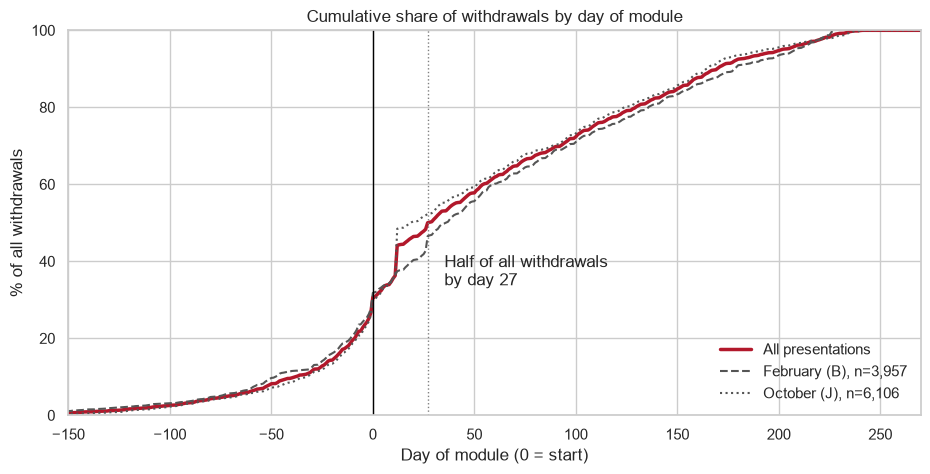

In [13]:
def cumulative_share(days):
    return days.value_counts().sort_index().cumsum() / len(days) * 100


fig, ax = plt.subplots(figsize=(11, 5))
overall_curve = cumulative_share(left['date_unregistration'])
ax.plot(overall_curve.index, overall_curve.values, color=OUTCOME_COLORS['Withdrawn'], linewidth=2.5,
        label='All presentations')

for ptype, style in [('February (B)', '--'), ('October (J)', ':')]:
    days = left.loc[left['presentation_type'] == ptype, 'date_unregistration']
    curve = cumulative_share(days)
    ax.plot(curve.index, curve.values, color='#555555', linestyle=style, linewidth=1.5,
            label=f'{ptype}, n={len(days):,}')

ax.axvline(0, color='black', linewidth=1)
ax.axvline(median_day, color='grey', linestyle=':', linewidth=1)
ax.annotate(f'Half of all withdrawals\nby day {median_day:.0f}', xy=(median_day, 50),
            xytext=(12, -45), textcoords='offset points')
ax.set(title='Cumulative share of withdrawals by day of module', xlabel='Day of module (0 = start)',
       ylabel='% of all withdrawals', ylim=(0, 100))
ax.set_xlim(-150, 270)
ax.legend(frameon=False, loc='lower right')
save(fig, 'withdrawal_timing')
plt.show()

The curve jumps sharply just after the start. Let's check which days drive that, and whether the jump is spread across presentations or concentrated in one intake.

In [14]:
print('Busiest withdrawal days:')
print(left['date_unregistration'].value_counts().head(5).to_string(), '\n')

day12 = left[left['date_unregistration'] == 12]
in_2014j = (day12['code_presentation'] == '2014J').sum()
print(f'Day 12: {len(day12):,} withdrawals, of which {in_2014j:,} ({in_2014j / len(day12):.0%}) '
      'are in the October 2014 presentations')
print(day12.groupby(['code_module', 'code_presentation']).size()
      .sort_values(ascending=False).head(6).to_string(), '\n')

spike = (left['date_unregistration'] == 12) & (left['code_presentation'] == '2014J')
rest = left[~spike]
print('Excluding the October 2014 day-12 spike:')
print(f"  share of withdrawals in days 0-27: {rest['date_unregistration'].between(0, 27).mean():.0%}")
print(f"  share of withdrawals by day 27:    {rest['date_unregistration'].le(27).mean():.0%}")
print(rest.groupby('presentation_type')['date_unregistration'].median()
      .rename('median withdrawal day').to_string())

Busiest withdrawal days:
date_unregistration
 12.0    788
 0.0     413
 27.0    170
-1.0     147
-2.0      99 

Day 12: 788 withdrawals, of which 723 (92%) are in the October 2014 presentations
code_module  code_presentation
FFF          2014J                217
BBB          2014J                181
CCC          2014J                135
DDD          2014J                109
EEE          2014J                 74
CCC          2014B                 19 

Excluding the October 2014 day-12 spike:
  share of withdrawals in days 0-27: 17%
  share of withdrawals by day 27:    46%
presentation_type
February (B)    37.0
October (J)     38.0


Half of all withdrawals (50%) happen by day 27: 27% before the module even starts and 23% in the first four weeks. This sets a hard limit on any week-4 early warning: it can only reach the other half, so the earliest withdrawals need a different approach, such as contact before the start and in week 1. The curve jumps sharply on day 12, with 788 withdrawals, but 723 of them (92%) come from the October 2014 presentations across five modules. That pattern points to an administrative event in that intake rather than individual decisions. Excluding it, 17% of withdrawals fall in days 0–27 and 46% happen by day 27 overall, so the early-withdrawal problem is real but slightly smaller than the raw figure suggests. February and October presentations withdraw on the same schedule once the spike is excluded (median day 37 vs 38); the apparent October gap (day 19) came entirely from that one event.

## 5. Does early engagement tell us who will leave?

Clicks are our best measure of engagement. But there's a trap here, called **survivorship**: students who withdraw stop clicking once they leave. If we average clicks over everyone in the Withdrawn group, the line falls towards zero partly because those students are gone, not because they were disengaged while enrolled.

So for each week, we only count students who were **still registered for that whole week**. Weeks where fewer than 50 students in a group are still registered are left blank.

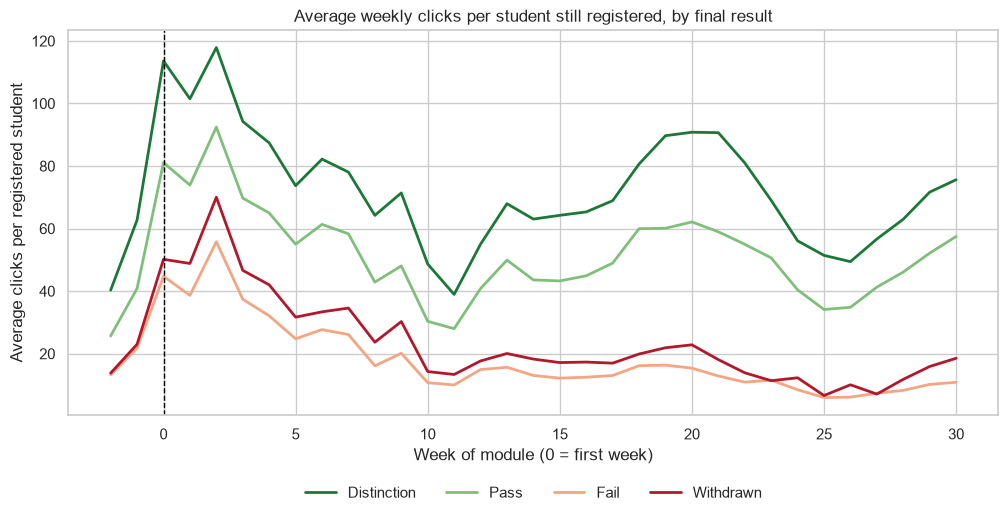

In [15]:
known = students[~((students['withdrawn'] == 1) & students['date_unregistration'].isna())].copy()
# Last week a student was registered for in full (inf = never left)
known['last_full_week'] = (np.floor(known['date_unregistration'] / 7) - 1).fillna(np.inf)

weeks = range(-2, 31)
w = weekly_clicks.merge(known[KEYS + ['final_result', 'last_full_week']], on=KEYS)
w = w[w['week'].between(-2, 30) & (w['week'] <= w['last_full_week'])]

clicks = (w.groupby(['week', 'final_result'])['clicks'].sum().unstack()
          .reindex(index=weeks, columns=OUTCOME_ORDER).fillna(0))
enrolled = (pd.DataFrame({wk: known.loc[known['last_full_week'] >= wk, 'final_result'].value_counts()
                          for wk in weeks}).T
            .reindex(index=weeks, columns=OUTCOME_ORDER))
avg_weekly = (clicks / enrolled).where(enrolled >= 50)

fig, ax = plt.subplots(figsize=(12, 5))
for outcome in OUTCOME_ORDER:
    ax.plot(avg_weekly.index, avg_weekly[outcome], label=outcome,
            color=OUTCOME_COLORS[outcome], linewidth=2)
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set(title='Average weekly clicks per student still registered, by final result',
       xlabel='Week of module (0 = first week)', ylabel='Average clicks per registered student')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
save(fig, 'weekly_clicks_by_outcome')
plt.show()

Even while still enrolled, students who later withdraw click far less than those who pass: about 50 clicks in week 0 against about 80, a gap that widens to roughly 3× by week 20. But clicks don’t distinguish withdrawal from failure: students who later withdraw are about as active as, or slightly more active than, those who stay and fail. So low engagement is a warning sign for not passing in general, and a click-based alert will flag a mix of future withdrawals and future fails. The dips shared by all groups around weeks 10–11 and 25–26 are likely breaks in the study calendar.

Now let's zoom in on the first four weeks (days 0–27), when the retention team would still have time to act.

For a fair comparison, we only include students **still registered at the end of day 27**. Everyone in this group had the full four weeks to engage. This is also the group our model will use in section 9.

Note what this means: in this group, "Withdrawn" means students who withdrew **on day 28 or later**. Students who left earlier are not in it. Section 9 counts how many withdrawals that leaves out.

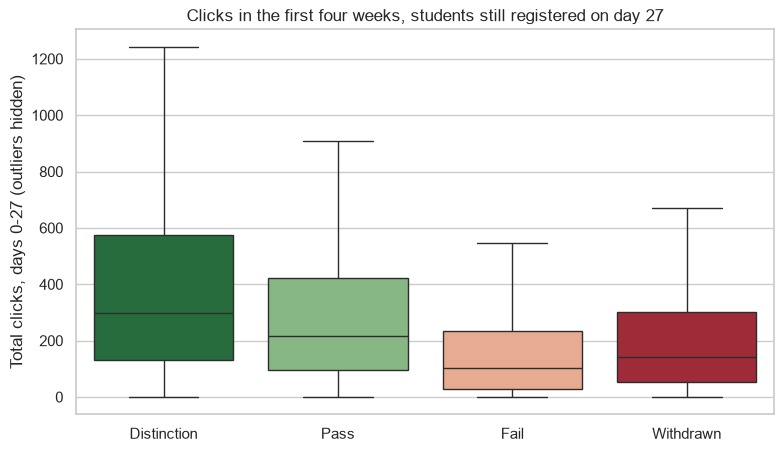

In [16]:
active28 = students[registered_on(students, 27)].copy()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=active28, x='final_result', y='early_clicks', order=OUTCOME_ORDER,
            hue='final_result', palette=OUTCOME_COLORS, legend=False, showfliers=False, ax=ax)
ax.set(title='Clicks in the first four weeks, students still registered on day 27', xlabel='',
       ylabel='Total clicks, days 0-27 (outliers hidden)')
save(fig, 'early_clicks_by_outcome')
plt.show()

In [17]:
early_summary = (active28.groupby('final_result')
                 .agg(enrolments=('early_clicks', 'size'),
                      median_early_clicks=('early_clicks', 'median'),
                      median_active_days=('early_active_days', 'median'),
                      pct_no_clicks=('early_clicks', lambda s: (s == 0).mean() * 100))
                 .reindex(OUTCOME_ORDER)
                 .round(1))
early_summary

,enrolments,median_early_clicks,median_active_days,pct_no_clicks
final_result,,,,
Distinction,3024,299.0,14.0,1.0
Pass,12361,217.0,11.0,1.6
Fail,7044,103.0,6.0,10.1
Withdrawn,5031,143.0,8.0,5.3


Among students still registered on day 27, those who withdrew later had a median of 143 clicks in the first four weeks, against 217 for students with a Pass (about a third less; 299 for Distinction), and were active on 8 days against 11. But early engagement is even lower among students who stay and fail (103 clicks, 6 active days, 10.1% with no clicks at all) than among those who later withdraw (5.3% with no clicks). So low early activity signals “at risk of not passing” more than “at risk of withdrawing”. A zero-activity alert in particular would catch only a small share of withdrawals. We’ll test this directly in section 10.

## 6. Which learning activities matter most?

Each resource in `vle` has an `activity_type`, such as a forum, quiz or content page. Let's compare how students who **passed** (Pass or Distinction), students who **failed** and students who **later withdrew** used the ten most-used activity types.

To keep it fair, we use the same group as above (still registered on day 27) and only the clicks from the first four weeks. That way both groups had the same amount of time.

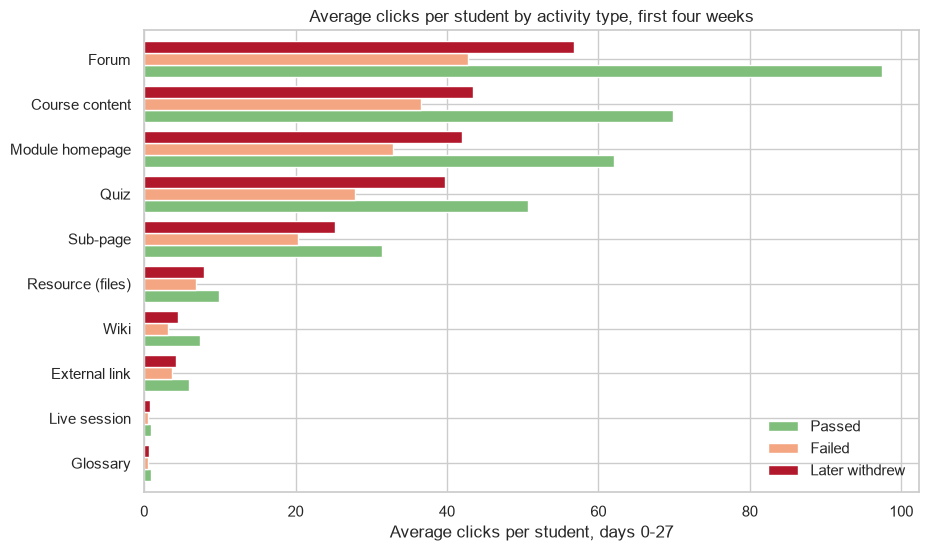

,Passed ÷ Withdrawn,Passed ÷ Failed
activity_type,,
Forum,1.7,2.3
Wiki,1.7,2.4
Glossary,1.6,1.9
Course content,1.6,1.9
Module homepage,1.5,1.9
External link,1.4,1.6
Live session,1.3,1.8
Quiz,1.3,1.8
Sub-page,1.2,1.6


In [18]:
active28['group'] = active28['final_result'].map(
    {'Distinction': 'Passed', 'Pass': 'Passed', 'Fail': 'Failed', 'Withdrawn': 'Withdrawn'})
group_size = active28['group'].value_counts()

by_type = (early_site_clicks
           .merge(vle[['id_site', 'activity_type']], on='id_site', how='left')
           .merge(active28[KEYS + ['group']], on=KEYS)
           .groupby(['activity_type', 'group'])['clicks'].sum()
           .div(group_size, level='group')
           .unstack('group'))

top_types = by_type['Passed'].nlargest(10).index
plot_df = by_type.loc[top_types, ['Passed', 'Failed', 'Withdrawn']].iloc[::-1]
plot_df = plot_df.rename(index={
    'forumng': 'Forum', 'oucontent': 'Course content', 'homepage': 'Module homepage',
    'quiz': 'Quiz', 'subpage': 'Sub-page', 'resource': 'Resource (files)', 'ouwiki': 'Wiki',
    'url': 'External link', 'oucollaborate': 'Live session', 'glossary': 'Glossary'})

fig, ax = plt.subplots(figsize=(10, 6))
plot_df.plot(kind='barh', width=0.8, ax=ax,
             color=[OUTCOME_COLORS['Pass'], OUTCOME_COLORS['Fail'], OUTCOME_COLORS['Withdrawn']])
ax.set(title='Average clicks per student by activity type, first four weeks',
       xlabel='Average clicks per student, days 0-27', ylabel='')
ax.legend(['Passed', 'Failed', 'Later withdrew'], frameon=False, loc='lower right')
save(fig, 'clicks_by_activity_type')
plt.show()

pd.DataFrame({'Passed ÷ Withdrawn': plot_df['Passed'] / plot_df['Withdrawn'],
              'Passed ÷ Failed': plot_df['Passed'] / plot_df['Failed']}
             ).sort_values('Passed ÷ Withdrawn', ascending=False).round(1)

Students who later withdraw are less active than students who pass across every activity type in the first four weeks, so the drop is general rather than tied to one feature. The biggest relative gaps are in forums and the wiki (1.7×), then course content and the glossary (1.6×), although wiki and glossary volumes are tiny. Forums also have the biggest absolute gap (about 97 vs 57 clicks per student). Quizzes (1.3×), sub-pages and resources (1.2×) show the smallest gaps.

Students who stay and fail are even less active than those who later withdraw, on every activity type: passing students click 1.5–2.4× as much as failing students, but only 1.2–1.7× as much as students who later withdraw. So low forum activity is a sign of disengagement in general, not evidence that forums keep students enrolled.

## 7. Does background raise the risk of withdrawing?

Let's check the withdrawal rate by deprivation band, number of previous attempts at the module, and credit load (how many credits the student is studying at once). Each bar is labelled with its number of enrolments, so small groups don't mislead us.

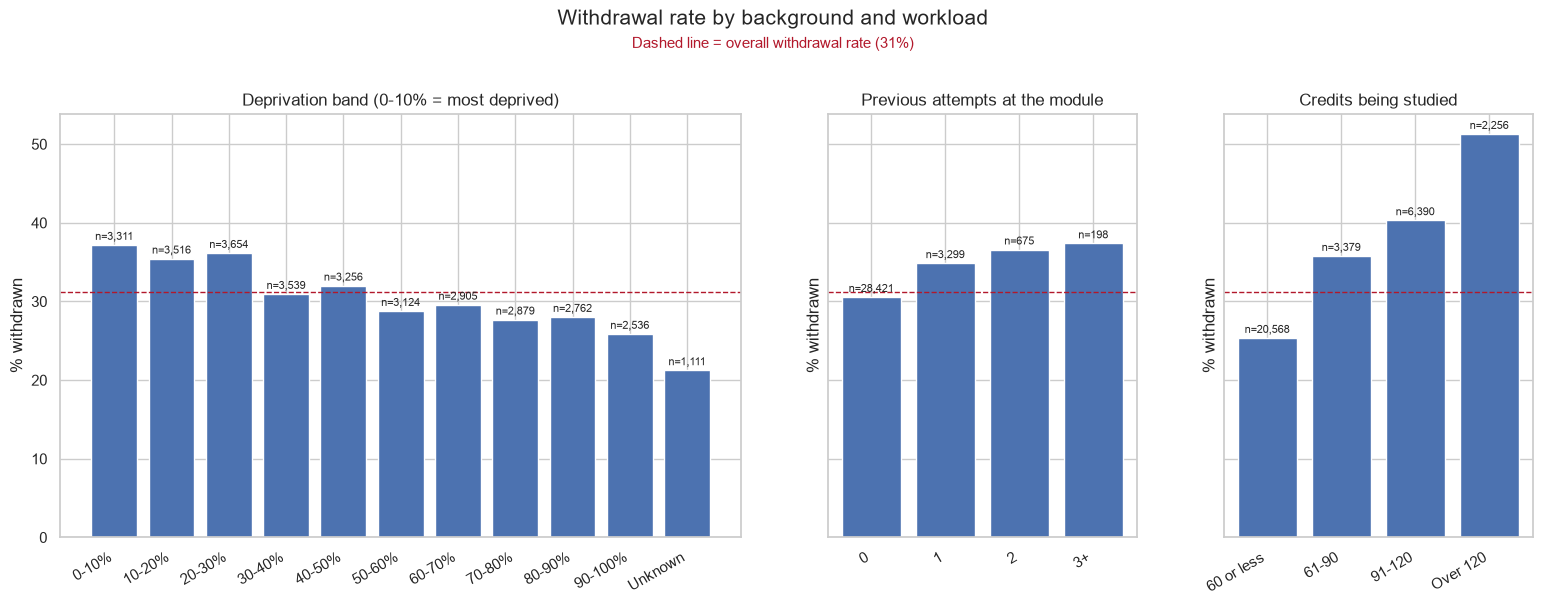

In [19]:
students['prev_attempts'] = students['num_of_prev_attempts'].clip(upper=3).map(
    {0: '0', 1: '1', 2: '2', 3: '3+'})
students['credit_load'] = pd.cut(students['studied_credits'], bins=[0, 60, 90, 120, np.inf],
                                 labels=['60 or less', '61-90', '91-120', 'Over 120'])
overall_rate = students['withdrawn'].mean() * 100


def rate_table(col, order):
    stats = students.groupby(col, observed=True)['withdrawn'].agg(['mean', 'size']).reindex(order)
    return pd.DataFrame({'% withdrawn': stats['mean'] * 100,
                         'enrolments': stats['size'].fillna(0).astype(int)})


panels = [('imd_band', imd_order, 'Deprivation band (0-10% = most deprived)'),
          ('prev_attempts', ['0', '1', '2', '3+'], 'Previous attempts at the module'),
          ('credit_load', ['60 or less', '61-90', '91-120', 'Over 120'], 'Credits being studied')]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True,
                         gridspec_kw={'width_ratios': [2.2, 1, 1]})
for ax, (col, order, title) in zip(axes, panels):
    t = rate_table(col, order)
    bars = ax.bar(t.index.astype(str), t['% withdrawn'], color='#4c72b0')
    ax.bar_label(bars, labels=[f'n={n:,}' for n in t['enrolments']], fontsize=8, padding=2)
    ax.axhline(overall_rate, color=OUTCOME_COLORS['Withdrawn'], linestyle='--', linewidth=1)
    ax.set(title=title, ylabel='% withdrawn', xlabel='')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

fig.suptitle('Withdrawal rate by background and workload', fontsize=15, y=1.07)
fig.text(0.5, 1.0, f'Dashed line = overall withdrawal rate ({overall_rate:.0f}%)',
         ha='center', fontsize=11, color=OUTCOME_COLORS['Withdrawn'])
save(fig, 'withdrawal_by_background')
plt.show()

One more factor as a table: how early the student registered. About a quarter of withdrawals happen before the module starts, so students who register early simply have longer to withdraw before day 0. To check that, we also show the withdrawal rate counting only withdrawals from day 0 onwards. Finally, we check where the Unknown deprivation band comes from.

In [20]:
students['registered'] = pd.cut(-students['date_registration'],
                                bins=[-np.inf, 0, 14, 30, 60, 90, np.inf],
                                labels=['On/after start', '1-14', '15-30', '31-60', '61-90', '90+'])
reg_order = students['registered'].cat.categories

# Withdrawal by registration timing: all withdrawals vs only those from day 0 onwards
after_start = students[~(students['date_unregistration'] < 0)]
after_rate = after_start.groupby('registered', observed=True)['withdrawn'].mean().reindex(reg_order) * 100
reg_table = rate_table('registered', reg_order).assign(**{'% withdrawn from day 0': after_rate})
print('Days registered before the module started')
print(reg_table.round(1).to_string(), '\n')

# Where is the deprivation band missing?
unknown = students.loc[students['imd_band'] == 'Unknown', 'region'].value_counts()
print(f'Unknown deprivation band by region ({unknown.sum():,} enrolments)')
print(unknown.head(5).to_frame('enrolments')
      .assign(**{'% of Unknown': (unknown.head(5) / unknown.sum() * 100).round(1)}).to_string())

Days registered before the module started
                % withdrawn  enrolments  % withdrawn from day 0
On/after start         20.8         236                    20.8
1-14                   21.1        1281                    19.7
15-30                  26.3        7505                    23.5
31-60                  28.2        8418                    23.8
61-90                  32.0        5374                    25.3
90+                    38.3        9734                    28.2 

Unknown deprivation band by region (1,111 enrolments)
                      enrolments  % of Unknown
region                                        
North Region                 731          65.8
Ireland                      266          23.9
South Region                  48           4.3
West Midlands Region          39           3.5
Scotland                      12           1.1


Workload is the strongest background factor: withdrawal doubles from 25.4% for students taking 60 credits or fewer to 51.3% for those taking over 120, and every group is large (2,256+). Deprivation shows a steady gradient, from about 37% in the most deprived band to about 26% in the least deprived. Repeat students withdraw somewhat more than first-timers (about 35–37% vs 30%), though the 3+ group is small (198). The “Unknown” deprivation band has the lowest rate (about 21%), but 90% of those students are in the North Region or Ireland, so it reflects where the index wasn’t recorded rather than anything about the students.

Early registration looks like a risk factor at first (38.3% withdrawal for 90+ days early vs 20.8% on or after the start), but mostly because early registrants have longer to drop out before the module begins. Counting only withdrawals from day 0, the gap shrinks to about 8 points (28.2% vs about 20%).

## 8. Does the first assessment predict the final result?

Every module has a first assessment (a tutor-marked or computer-marked assignment). Let's first check **when** it's due in each module presentation.

In [21]:
first = (assessments[assessments['assessment_type'] != 'Exam']
         .dropna(subset=['date'])
         .sort_values(['date', 'id_assessment'])
         .groupby(['code_module', 'code_presentation']).head(1)
         [['code_module', 'code_presentation', 'id_assessment', 'date']]
         .rename(columns={'id_assessment': 'first_assessment', 'date': 'first_due'}))

first.pivot(index='code_module', columns='code_presentation', values='first_due')

code_presentation,2013B,2013J,2014B,2014J
code_module,,,,
AAA,NaN,19.0,NaN,19.0
BBB,19.0,19.0,12.0,19.0
CCC,NaN,NaN,18.0,18.0
DDD,23.0,25.0,25.0,20.0
EEE,NaN,33.0,33.0,33.0
FFF,19.0,19.0,24.0,24.0
GGG,NaN,61.0,61.0,61.0


In some modules the first assessment is due after day 27. So a missed submission can't be part of a week-4 warning everywhere. We'll treat this section as a **descriptive** finding and keep it out of the week-4 model, to avoid leakage (using information the team wouldn't have yet).

An alert can only act on what the team knows on the due date. So a student counts as **not submitted by the due date** if there's no submission at all **or** it arrived after the due date: on the day the alert fires, a late submitter looks exactly like someone who never submits. (`GRACE_DAYS` can allow a few days' grace; we use 0.)

To be fair, we only keep students who were **still registered at the end of the due date**. Otherwise, students who had already left would count as "not submitted", which would exaggerate the effect.

In [22]:
GRACE_DAYS = 0
MISSED = 'Not submitted by due date'

fa = students.merge(first, on=['code_module', 'code_presentation'])
# Still registered at the end of the due date (same rule as registered_on)
date_known = ~((fa['withdrawn'] == 1) & fa['date_unregistration'].isna())
fa = fa[date_known & (fa['date_unregistration'].isna() | (fa['date_unregistration'] > fa['first_due']))].copy()

subs = student_assessment[['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']].rename(
    columns={'id_assessment': 'first_assessment', 'score': 'first_score'})
fa = fa.merge(subs, on=['first_assessment', 'id_student'], how='left')

# What the team can see on the due date: only submissions that arrived on time
on_time = fa['date_submitted'].notna() & (fa['date_submitted'] <= fa['first_due'] + GRACE_DAYS)

band_order = [MISSED, 'Below 40', '40-69', '70+']
fa['first_result'] = pd.cut(fa['first_score'], bins=[-1, 39.99, 69.99, 100],
                            labels=band_order[1:]).astype(str)
fa.loc[~on_time, 'first_result'] = MISSED
fa = fa[fa['first_result'].isin(band_order)]

late = (fa['date_submitted'] > fa['first_due'] + GRACE_DAYS).sum()
never = fa['date_submitted'].isna().sum()
print(f'{len(fa):,} enrolments still registered at the end of the first due date')
print(f'Not submitted by due date: {never:,} never submitted + {late:,} submitted late')
print(f"{int((fa['is_banked'] == 1).sum()):,} scores were banked from an earlier attempt "
      '(recorded on day -1) and count as on time: those students do not need to submit again')
fa['first_result'].value_counts().reindex(band_order).to_frame('enrolments')

27,753 enrolments still registered at the end of the first due date
Not submitted by due date: 2,731 never submitted + 6,187 submitted late
493 scores were banked from an earlier attempt (recorded on day -1) and count as on time: those students do not need to submit again


,enrolments
first_result,
Not submitted by due date,8918
Below 40,867
40-69,4540
70+,13428


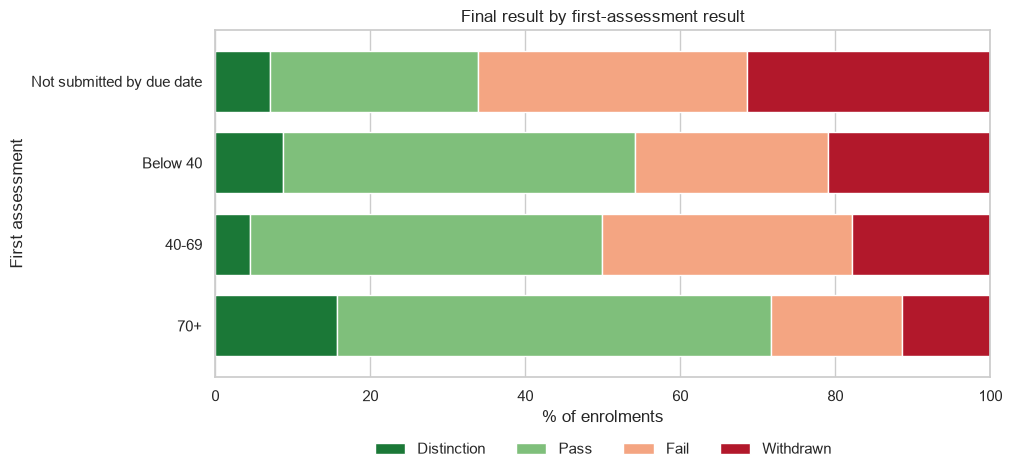

final_result,Distinction,Pass,Fail,Withdrawn
first_result,,,,
Not submitted by due date,7.1,26.8,34.6,31.5
Below 40,8.8,45.3,24.9,21.0
40-69,4.5,45.4,32.3,17.9
70+,15.7,56.0,16.9,11.4


In [23]:
by_first = (pd.crosstab(fa['first_result'], fa['final_result'], normalize='index')
            .reindex(index=band_order, columns=OUTCOME_ORDER).fillna(0) * 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
by_first.plot(kind='barh', stacked=True, width=0.75, ax=ax,
              color=[OUTCOME_COLORS[c] for c in OUTCOME_ORDER])
ax.set(title='Final result by first-assessment result', xlabel='% of enrolments',
       ylabel='First assessment', xlim=(0, 100))
ax.invert_yaxis()
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
save(fig, 'outcome_by_first_assessment')
plt.show()

by_first.round(1)

Missing the deadline covers two different groups: students who never submit, and students who submit a few days late. Let's split them.

In [24]:
fa['status'] = np.select([fa['date_submitted'].isna(), fa['date_submitted'] > fa['first_due'] + GRACE_DAYS],
                         ['Never submitted', 'Submitted late'], 'On time')
days_late = (fa['date_submitted'] - fa['first_due'])[fa['status'] == 'Submitted late']
print(f'Late submitters: median {days_late.median():.0f} days late, {(days_late <= 7).mean():.0%} within a week')

status_table = (pd.crosstab(fa['status'], fa['final_result'], normalize='index')
                .reindex(index=['Never submitted', 'Submitted late', 'On time'], columns=OUTCOME_ORDER) * 100)
status_table['Passed'] = status_table['Distinction'] + status_table['Pass']
status_table.round(1)

Late submitters: median 3 days late, 89% within a week


final_result,Distinction,Pass,Fail,Withdrawn,Passed
status,,,,,
Never submitted,0.3,4.6,53.6,41.6,4.8
Submitted late,10.1,36.6,26.3,27.0,46.7
On time,12.7,52.9,21.0,13.4,65.6


Of the 27,753 enrolments still registered at the end of the first due date, 8,918 (32%) hadn't submitted by then: 2,731 never submitted and 6,187 submitted late. Missing the deadline is a clear warning but not a verdict: 31.5% of these students went on to withdraw and 34.6% to fail, yet a third (33.9%) still passed. The split shows why: only 4.8% of students who never submitted passed (41.6% withdrew), against 46.7% of late submitters, who were mostly just a few days behind (median 3 days late, 89% within a week). Among students who submitted on time, the score grades the risk, with withdrawal falling from 21.0% (below 40) to 17.9% (40–69) to 11.4% (70+); students who missed the deadline withdrew at 2.8× the rate of those scoring 70+.

The first assessment is due by day 25 in five modules but on day 33 in EEE and day 61 in GGG, so it can only serve as an early alert in some modules. That's why it isn't a feature in the week-4 model, and why section 10 tests it separately for early and late due dates.

## 9. Can we flag at-risk students by the end of week 4?

Before building anything, let's be clear about what a week-4 alert **can't** do. Students who withdraw on or before day 27 are gone before it could fire. Let's count them.

In [25]:
all_withdrawn = students[students['withdrawn'] == 1]
dated = all_withdrawn['date_unregistration'].dropna()

reach = pd.DataFrame({
    'withdrawals': [(dated < 0).sum(), dated.between(0, 27).sum(), (dated >= 28).sum(),
                    all_withdrawn['date_unregistration'].isna().sum()],
}, index=['Before the module started', 'Days 0-27', 'Day 28 or later (a week-4 alert can reach)',
          'No date recorded'])
reach['% of all withdrawals'] = (reach['withdrawals'] / len(all_withdrawn) * 100).round(1)
reach

,withdrawals,% of all withdrawals
Before the module started,2676,26.3
Days 0-27,2356,23.2
Day 28 or later (a week-4 alert can reach),5031,49.5
No date recorded,93,0.9


Only about half of withdrawals can be reached by a week-4 alert. 2,676 (26.3%) happen before the module even starts and 2,356 (23.2%) in the first four weeks, leaving 5,031 (49.5%) that happen on day 28 or later. Those early withdrawals need a different approach, such as contact before the start and in week 1. The rest of this section focuses on the reachable half.

Now the model. Three rules keep it honest:

1. **Only information available by the end of day 27.** Clicks and active days in days 0–27, clicks in days 21–27 (the most recent week), registration timing, previous attempts, credit load, deprivation band, age band, education and module. Nothing from later, so no first-assessment result.
2. **Only students still registered at the end of day 27.** Students who had already left are not something we can predict any more.
3. **Train on 2013, test on 2014.** A random split would let the model see the same module presentations in training and testing. Training on one year and testing on the next is closer to how the team would really use it.

We use logistic regression with balanced class weights, because withdrawals are the minority class. We report **precision** as well as **recall** on the Withdrew class, because outreach takes staff time: flagging too many students who would have stayed anyway has a cost.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

last_week = (weekly_clicks.loc[weekly_clicks['week'] == 3, KEYS + ['clicks']]
             .rename(columns={'clicks': 'clicks_days_21_27'}))
model_df = (students[registered_on(students, 27)]
            .merge(last_week, on=KEYS, how='left')
            .fillna({'clicks_days_21_27': 0}))

num_cols = ['early_clicks', 'early_active_days', 'clicks_days_21_27', 'date_registration',
            'num_of_prev_attempts', 'studied_credits']
cat_cols = ['imd_band', 'age_band', 'highest_education', 'code_module']
model_df[cat_cols] = model_df[cat_cols].astype(object)

is_train = model_df['year'] == 2013
X_train, y_train = model_df.loc[is_train, num_cols + cat_cols], model_df.loc[is_train, 'withdrawn']
X_test, y_test = model_df.loc[~is_train, num_cols + cat_cols], model_df.loc[~is_train, 'withdrawn']
print(f'Train (2013): {len(X_train):,} enrolments, {y_train.mean():.0%} later withdrew')
print(f'Test (2014):  {len(X_test):,} enrolments, {y_test.mean():.0%} later withdrew')

new_modules = sorted(set(X_test['code_module']) - set(X_train['code_module']))
print(f"Modules in the 2014 test set that never appear in 2013 training: {', '.join(new_modules) or 'none'}")

Train (2013): 11,815 enrolments, 17% later withdrew
Test (2014):  15,645 enrolments, 19% later withdrew
Modules in the 2014 test set that never appear in 2013 training: CCC


If any modules appear only in 2014, the model has never seen them, so its performance there may look worse for reasons unrelated to the features. We'll report results for the full test set **and** for the modules shared by both years.

In [27]:
preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore')), cat_cols),
])
model = make_pipeline(preprocess, LogisticRegression(max_iter=1000, class_weight='balanced'))
model.fit(X_train, y_train)

shared = ~X_test['code_module'].isin(new_modules)
print('All 2014 modules')
print(classification_report(y_test, model.predict(X_test), target_names=['Stayed', 'Withdrew']))
if new_modules:
    print('Modules shared with 2013 only')
    print(classification_report(y_test[shared], model.predict(X_test[shared]),
                                target_names=['Stayed', 'Withdrew']))

from sklearn.metrics import roc_auc_score
proba = model.predict_proba(X_test)[:, 1]
print(f'ROC AUC, withdrawal model: {roc_auc_score(y_test, proba):.3f} (all 2014 modules)')
if new_modules:
    print(f'ROC AUC, withdrawal model: {roc_auc_score(y_test[shared], proba[shared.to_numpy()]):.3f} '
          '(shared modules only)')

All 2014 modules
              precision    recall  f1-score   support

      Stayed       0.84      0.68      0.75     12625
    Withdrew       0.26      0.47      0.33      3020

    accuracy                           0.64     15645
   macro avg       0.55      0.57      0.54     15645
weighted avg       0.73      0.64      0.67     15645

Modules shared with 2013 only
              precision    recall  f1-score   support

      Stayed       0.88      0.63      0.74     10166
    Withdrew       0.23      0.57      0.33      1984

    accuracy                           0.62     12150
   macro avg       0.56      0.60      0.53     12150
weighted avg       0.78      0.62      0.67     12150



ROC AUC, withdrawal model: 0.614 (all 2014 modules)
ROC AUC, withdrawal model: 0.645 (shared modules only)


The default cut-off flags anyone with a predicted risk above 50%. In practice, a retention team has a fixed amount of time for outreach, so a more useful question is: **if we contact the riskiest X% of students, how many of them would really have withdrawn (precision), and what share of withdrawals do we reach (recall)?**

Precision only means something next to the **baseline**: if 25% of students withdraw anyway, a precision of 40% is good but not dramatic. **Lift** (precision ÷ baseline) shows how many times better than random contact the model is.

In [28]:
test = model_df.loc[~is_train, KEYS + ['withdrawn']].assign(risk=model.predict_proba(X_test)[:, 1])


def flag_table(df, shares=(0.10, 0.20, 0.30, 0.40)):
    baseline = df['withdrawn'].mean() * 100
    rows = []
    for share in shares:
        flagged = df.nlargest(int(round(share * len(df))), 'risk')
        precision = flagged['withdrawn'].mean() * 100
        rows.append({'Flag the riskiest': f'{share:.0%}',
                     'Students flagged': len(flagged),
                     'Precision: % of flagged who withdrew': round(precision, 1),
                     'Baseline withdrawal rate': round(baseline, 1),
                     'Lift': round(precision / baseline, 2),
                     'Recall: % of withdrawals reached': round(
                         flagged['withdrawn'].sum() / df['withdrawn'].sum() * 100, 1)})
    return pd.DataFrame(rows).set_index('Flag the riskiest')


tables = {'All 2014 modules': flag_table(test)}
if new_modules:
    tables['Shared modules only'] = flag_table(test[~test['code_module'].isin(new_modules)])
pd.concat(tables)

Students flagged  \
                    Flag the riskiest                     
All 2014 modules    10%                            1564   
                    20%                            3129   
                    30%                            4694   
                    40%                            6258   
Shared modules only 10%                            1215   
                    20%                            2430   
                    30%                            3645   
                    40%                            4860   

                                       Precision: % of flagged who withdrew  \
                    Flag the riskiest                                         
All 2014 modules    10%                                                32.1   
                    20%                                                28.4   
                    30%                                                26.7   
                    40%                                                25.2   
Shared modules only 10%                                                33.0   
                    20%                                                28.0   
                    30%                                                25.5   
                    40%                                                23.3   

                                       Baseline withdrawal rate  Lift  \
                    Flag the riskiest                                   
All 2014 modules    10%                                    19.3  1.66   
                    20%                                    19.3  1.47   
                    30%                                    19.3  1.38   
                    40%                                    19.3  1.31   
Shared modules only 10%                                    16.3  2.02   
                    20%                                    16.3  1.71   
                    30%                                    16.3  1.56   
                    40%                                    16.3  1.42   

                                       Recall: % of withdrawals reached  
                    Flag the riskiest                                    
All 2014 modules    10%                                            16.6  
                    20%                                            29.5  
                    30%                                            41.5  
                    40%                                            52.3  
Shared modules only 10%                                            20.2  
                    20%                                            34.3  
                    30%                                            46.9  
                    40%                                            57.0

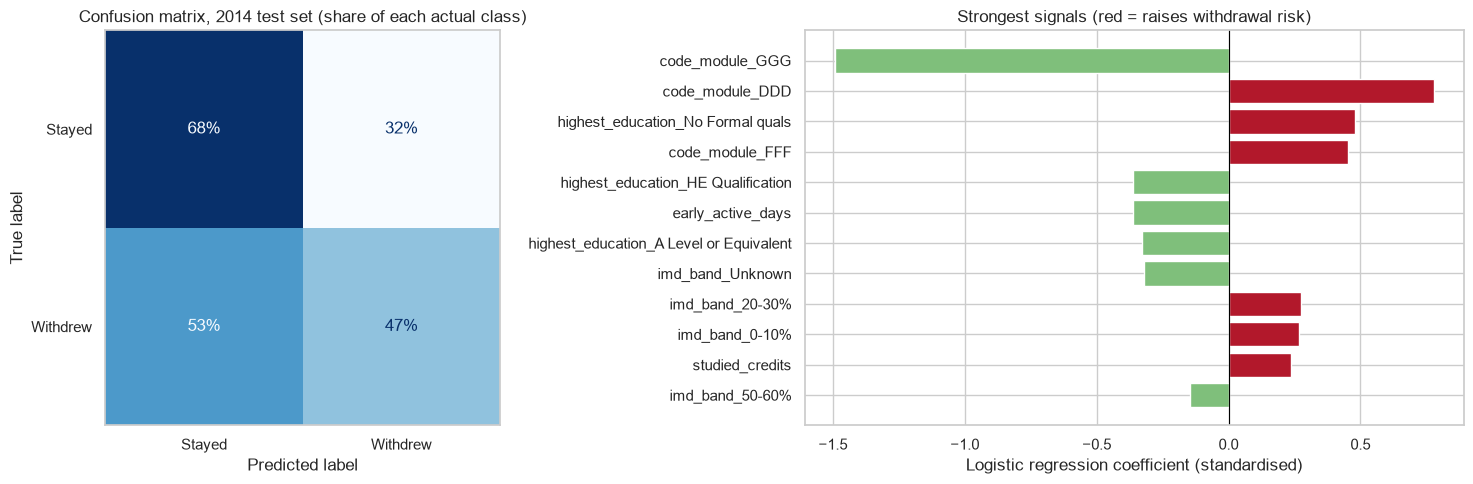

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['Stayed', 'Withdrew'],
                                      normalize='true', values_format='.0%', cmap='Blues',
                                      colorbar=False, ax=axes[0])
axes[0].set(title='Confusion matrix, 2014 test set (share of each actual class)')
axes[0].grid(False)

names = model[0].get_feature_names_out()
coefs = pd.Series(model[-1].coef_[0], index=names)
coefs.index = coefs.index.str.replace('num__', '').str.replace('cat__', '')
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:12]).iloc[::-1]
axes[1].barh(top.index, top.values,
             color=np.where(top.values > 0, OUTCOME_COLORS['Withdrawn'], OUTCOME_COLORS['Pass']))
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set(title='Strongest signals (red = raises withdrawal risk)',
            xlabel='Logistic regression coefficient (standardised)')

fig.tight_layout()
save(fig, 'week4_model')
plt.show()

**Reading the model.** At the default cut-off (50% predicted risk), the model catches 47% of later withdrawals but also flags 32% of students who stay. The strongest signals are module identity: GGG strongly lowers the risk and DDD and FFF raise it, which mostly reflects each module's own withdrawal rate. Among student features, having no formal qualifications, living in the most deprived bands (0–10%, 20–30%) and a heavier credit load raise the risk, while HE or A-level qualifications and more active days in the first four weeks lower it. The engagement effect is split across three related columns (clicks, active days and clicks in days 21–27), so each looks smaller on its own than their combined effect. The Unknown deprivation band's negative weight reflects where the index wasn't recorded (section 7), not the students.

One caution: the numeric features are standardised (one unit = one standard deviation), but the module, education and deprivation columns are 0/1 flags compared with a reference group, so bar lengths aren't strictly comparable between the two kinds.

**Alternative target:** same features and split, but predicting *not passing* (Fail or Withdrawn) instead of withdrawal alone.

In [30]:
from sklearn.base import clone

# Same features and split; target = did not pass (Fail or Withdrawn)
not_passed = model_df['final_result'].isin(['Fail', 'Withdrawn']).astype(int)
model_np = clone(model).fit(X_train, not_passed[is_train])

# flag_table counts the 'withdrawn' column, so we pass the not-passed flag under that name
test_np = model_df.loc[~is_train, KEYS].assign(withdrawn=not_passed[~is_train].values,
                                               risk=model_np.predict_proba(X_test)[:, 1])
print(f'ROC AUC, not-passing model: {roc_auc_score(not_passed[~is_train], test_np["risk"]):.3f} '
      f'(withdrawal model: {roc_auc_score(y_test, proba):.3f}). '
      'AUC does not depend on the baseline rate, so it compares the two targets fairly.')

(flag_table(test_np)
 .rename(columns=lambda c: c.replace('withdrawals', 'non-passes')
                            .replace('withdrawal', 'not-passing')
                            .replace('withdrew', 'did not pass')))

ROC AUC, not-passing model: 0.713 (withdrawal model: 0.614). AUC does not depend on the baseline rate, so it compares the two targets fairly.


,Students flagged,Precision: % of flagged who did not pass,Baseline not-passing rate,Lift,Recall: % of non-passes reached
Flag the riskiest,,,,,
10%,1564,78.4,43.7,1.80,18.0
20%,3129,70.5,43.7,1.62,32.3
30%,4694,65.8,43.7,1.51,45.2
40%,6258,62.3,43.7,1.43,57.1


For the withdrawals a week-4 alert can reach, a simple model trained on 2013 and tested on 2014 gives modest results. Flagging the riskiest 20% of students gives a precision of 28.4% against a 19.3% baseline (1.47× lift) and reaches 29.5% of later withdrawals. On the modules seen in training the picture is mixed: lift at 20% is higher (1.71×, against a lower 16.3% baseline), but at the default cut-off precision is slightly lower (23% vs 26%). So the new 2014 module CCC isn't the main reason the model is weak.

The main limit is that students who withdraw after week 4 look much like students who stay and fail (section 5), so early activity can't reliably separate the two. Predicting *not passing* (Fail or Withdrawn) with the same features gives a more useful alert in practice: 70.5% of the riskiest 20% go on to not pass, against a 43.7% baseline, and they account for 32.3% of all non-passes. Part of that is simply the higher baseline: lift is only a little higher (1.62× vs 1.47×). ROC AUC, which doesn't depend on the baseline, confirms it: 0.713 for not passing against 0.614 for withdrawal (0.645 on shared modules only). Both models are weak (0.5 is chance), so either is best used to prioritise outreach, not to decide it. Either way, a week-4 alert is best framed as "at risk of not passing", with the follow-up deciding whether each student needs retention or study support.

## 10. Do simple alert rules work?

A model isn't the only option. A retention team could also use simple rules. Let's test three, and compare them with the model under the same conditions:

- **Same test data:** every rule is measured on the **2014** presentations, like the model. Any threshold is chosen using **2013 only**.
- **Only when the rule can fire:** each rule is checked on students still registered on the day it becomes available. The "Can act from" column says when that is.
- **Missed first assessment** is split by due date. Where the assessment is due by day 27 it can sit alongside the week-4 alerts; where it's due later, it's a later alert and must be read that way.

For each rule we report the share flagged, **precision**, the **baseline** withdrawal rate in that group, **lift**, **recall** (share of that group's withdrawals caught) and **reach** (share of **all** 2014 withdrawals caught, including the ones that happened before the rule could fire).

First, the activity rule's threshold. A score like F1 isn't a fair way to choose it, because it rewards flagging more students (flagging everyone would score higher). Instead we fix the **share of students flagged**: we take the threshold whose 2013 flag rate is closest to 20%, the same share as the model's riskiest 20%. The table shows 3 to 7 active days for both years, with lift, so you can see how much the threshold matters.

In [31]:
pop_day27 = students[registered_on(students, 27)]

rows = []
for threshold in range(3, 8):
    for year in [2013, 2014]:
        group = pop_day27[pop_day27['year'] == year]
        flagged = group['early_active_days'] < threshold
        precision = group.loc[flagged, 'withdrawn'].mean() * 100
        rows.append({'Fewer than N active days': threshold, 'Year': year,
                     '% flagged': flagged.mean() * 100, 'Precision %': precision,
                     'Lift': precision / (group['withdrawn'].mean() * 100),
                     'Recall %': group.loc[flagged, 'withdrawn'].sum() / group['withdrawn'].sum() * 100})
sensitivity = pd.DataFrame(rows)

flag_2013 = sensitivity[sensitivity['Year'] == 2013].set_index('Fewer than N active days')['% flagged']
best_threshold = (flag_2013 - 20).abs().idxmin()
print(f'Threshold chosen on 2013 data (flag rate closest to 20%): fewer than {best_threshold} active days')

sensitivity.pivot(index='Fewer than N active days', columns='Year',
                  values=['% flagged', 'Precision %', 'Lift', 'Recall %']).round(2)

Threshold chosen on 2013 data (flag rate closest to 20%): fewer than 5 active days


% flagged        Precision %         Lift        \
Year                          2013   2014        2013   2014  2013  2014   
Fewer than N active days                                                   
3                            13.03  12.37       20.66  22.12  1.21  1.15   
4                            17.49  17.42       21.14  22.39  1.24  1.16   
5                            22.09  23.09       20.96  22.72  1.23  1.18   
6                            26.87  29.28       20.35  22.44  1.20  1.16   
7                            32.04  35.35       19.99  22.71  1.17  1.18   

                         Recall %         
Year                         2013   2014  
Fewer than N active days                  
3                           15.81  14.17  
4                           21.73  20.20  
5                           27.20  27.19  
6                           32.12  34.04  
7                           37.64  41.59

Precision stays at 20–23% and lift between 1.15× and 1.24× for every threshold from 3 to 7 active days, in both years. So the exact threshold barely matters: low activity on its own is a weak signal of withdrawal. We use 5 days, which flags about 22–23% of students.

Now the comparison, all on 2014. Each rule is tested against **two outcomes**, withdrawal and not passing, and every row is compared with the matching model **flagging the same share of students** ("Model lift at same % flagged"), so a rule that flags more or fewer students isn't unfairly helped or penalised. The model is scored on **each rule's own students**, so the comparison is like-for-like. Because the model needs four weeks of data, students who left between the day a rule fires and day 27 can't be scored, so they drop out of the model comparison only.

In [32]:
in_2014 = students['year'] == 2014
NOT_PASSED = ['Fail', 'Withdrawn']

# Model scores on the 2014 test set, for both targets
scored = model_df.loc[~is_train, KEYS + ['final_result', 'withdrawn']].assign(
    risk_withdrawal=model.predict_proba(X_test)[:, 1],
    risk_not_passed=model_np.predict_proba(X_test)[:, 1])
scored['not_passed'] = scored['final_result'].isin(NOT_PASSED).astype(int)


def model_lift_on(population, share, target):
    """Lift of the matching model when it flags the same share of the rule's own students."""
    risk = 'risk_withdrawal' if target == 'withdrawn' else 'risk_not_passed'
    pop = population[KEYS].merge(scored[KEYS + [risk, 'withdrawn', 'not_passed']], on=KEYS)
    top = pop.nlargest(max(1, int(round(share * len(pop)))), risk)
    return top[target].mean() / pop[target].mean()


def evaluate(rule, can_act, population, flagged, target):
    population = population.assign(not_passed=population['final_result'].isin(NOT_PASSED).astype(int))
    flagged = flagged.fillna(False).astype(bool).to_numpy()
    hits = population.loc[flagged, target]
    all_2014 = (students.loc[in_2014, 'final_result'].isin(NOT_PASSED).sum() if target == 'not_passed'
                else students.loc[in_2014, 'withdrawn'].sum())
    baseline = population[target].mean() * 100
    precision = hits.mean() * 100
    share = flagged.mean()
    return {'Rule': rule, 'Can act from': can_act,
            'Students checked': len(population),
            '% flagged': round(share * 100, 1),
            'Precision %': round(precision, 1),
            'Baseline %': round(baseline, 1),
            'Lift': round(precision / baseline, 2),
            'Model lift at same % flagged': round(model_lift_on(population, share, target), 2),
            'Recall %': round(hits.sum() / population[target].sum() * 100, 1),
            'Reach: % of all 2014 cases': round(hits.sum() / all_2014 * 100, 1)}


# Rule 1: no clicks at all in the second week (days 7-13)
week2 = weekly_clicks.loc[weekly_clicks['week'] == 1, KEYS + ['clicks']]
pop1 = (students[in_2014 & registered_on(students, 13)]
        .merge(week2, on=KEYS, how='left').fillna({'clicks': 0}))

# Rule 2: low activity in the first four weeks (threshold chosen on 2013 at a ~20% flag rate)
pop2 = pop_day27[pop_day27['year'] == 2014]

# Rule 3: first assessment not submitted by the due date, split by when it was due
fa_2014 = fa[fa['year'] == 2014]
fa_early, fa_late = fa_2014[fa_2014['first_due'] <= 27], fa_2014[fa_2014['first_due'] > 27]


def rules_table(target):
    results = [
        evaluate('No clicks in week 2 (days 7-13)', 'Day 14', pop1, pop1['clicks'] == 0, target),
        evaluate(f'Active on fewer than {best_threshold} of days 0-27', 'Day 28', pop2,
                 pop2['early_active_days'] < best_threshold, target),
    ]
    for label, group in [('due by day 27', fa_early), ('due after day 27', fa_late)]:
        if len(group):
            lo, hi = group['first_due'].min(), group['first_due'].max()
            days = f'Due date (day {lo:.0f})' if lo == hi else f'Due date (days {lo:.0f}-{hi:.0f})'
            results.append(evaluate(f'Missed first assessment, {label}', days, group,
                                    group['first_result'] == MISSED, target))
    risk = 'risk_withdrawal' if target == 'withdrawn' else 'risk_not_passed'
    results.append(evaluate('Model: riskiest 20%', 'Day 28', scored,
                            scored[risk] >= scored[risk].quantile(0.80), target))
    return pd.DataFrame(results).set_index('Rule')


print('Outcome: WITHDRAWAL')
display(rules_table('withdrawn'))
print('Outcome: NOT PASSING (Fail or Withdrawn)')
rules_table('not_passed')

Outcome: WITHDRAWAL


,Can act from,Students checked,% flagged,Precision %,Baseline %,Lift,Model lift at same % flagged,Recall %,Reach: % of all 2014 cases
Rule,,,,,,,,,
No clicks in week 2 (days 7-13),Day 14,15942,19.3,24.7,20.8,1.19,1.48,22.9,11.8
Active on fewer than 5 of days 0-27,Day 28,15645,23.1,22.7,19.3,1.18,1.44,27.2,12.8
"Missed first assessment, due by day 27",Due date (days 12-25),12667,39.1,32.5,22.1,1.47,1.23,57.5,25.0
"Missed first assessment, due after day 27",Due date (days 33-61),3094,21.7,23.2,10.8,2.15,1.94,46.6,2.4
Model: riskiest 20%,Day 28,15645,20.0,28.4,19.3,1.47,1.47,29.5,13.8


Outcome: NOT PASSING (Fail or Withdrawn)


,Can act from,Students checked,% flagged,Precision %,Baseline %,Lift,Model lift at same % flagged,Recall %,Reach: % of all 2014 cases
Rule,,,,,,,,,
No clicks in week 2 (days 7-13),Day 14,15942,19.3,64.7,44.7,1.45,1.63,27.9,19.4
Active on fewer than 5 of days 0-27,Day 28,15645,23.1,63.8,43.7,1.46,1.57,33.8,22.5
"Missed first assessment, due by day 27",Due date (days 12-25),12667,39.1,60.6,45.9,1.32,1.41,51.6,29.3
"Missed first assessment, due after day 27",Due date (days 33-61),3094,21.7,78.5,36.6,2.15,1.68,46.6,5.1
Model: riskiest 20%,Day 28,15645,20.0,70.5,43.7,1.62,1.62,32.3,21.5


The same comparison as a chart: each alert's lift against the model flagging the same share of the same students.

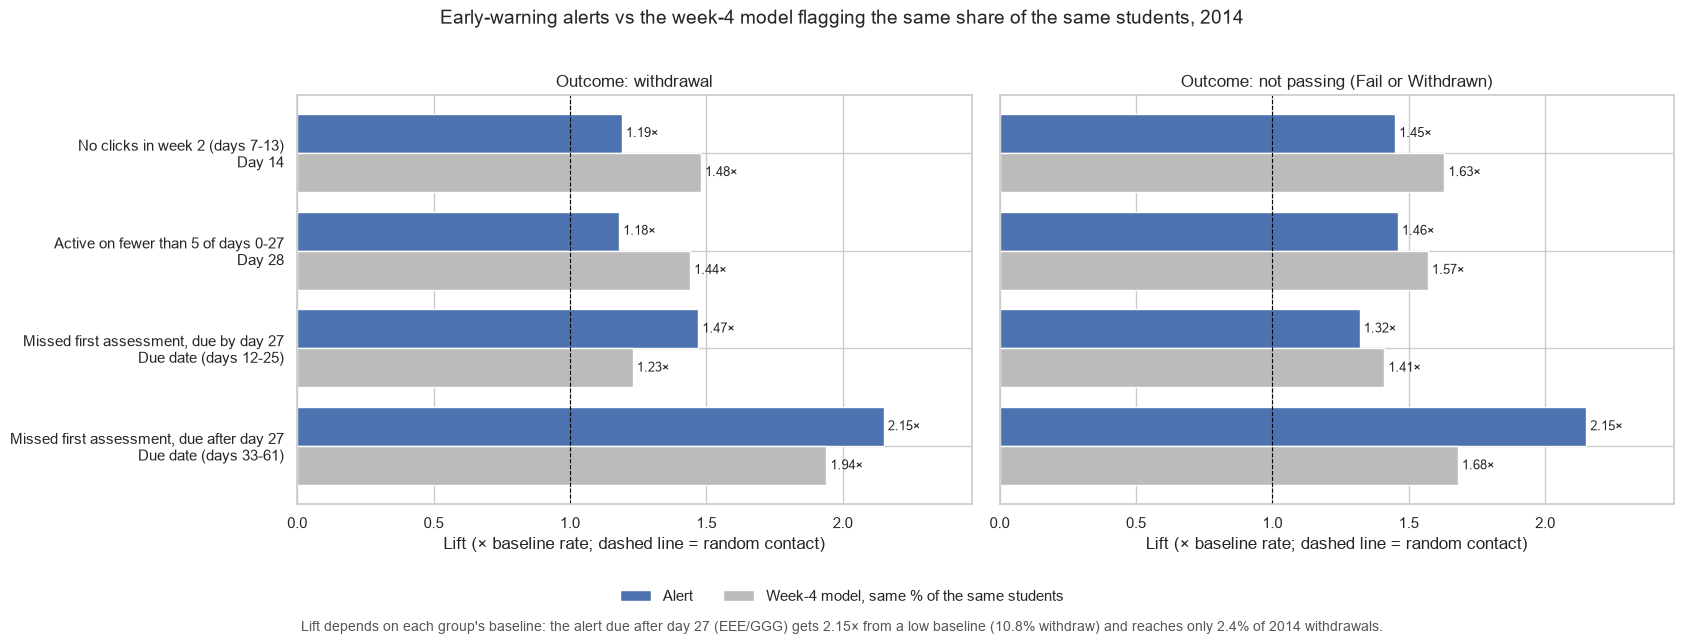

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True, sharex=True)
top = 0
for ax, (target, title) in zip(axes, [('withdrawn', 'Outcome: withdrawal'),
                                      ('not_passed', 'Outcome: not passing (Fail or Withdrawn)')]):
    # The model row is left out: it would only compare the model with itself
    t = rules_table(target).drop('Model: riskiest 20%').iloc[::-1]
    y = np.arange(len(t))
    alert = ax.barh(y + 0.2, t['Lift'], height=0.4, color='#4c72b0', label='Alert')
    model_bars = ax.barh(y - 0.2, t['Model lift at same % flagged'], height=0.4, color='#bbbbbb',
                         label='Week-4 model, same % of the same students')
    for bars in (alert, model_bars):
        ax.bar_label(bars, fmt='%.2f×', padding=3, fontsize=9)
    ax.axvline(1, color='black', linewidth=0.8, linestyle='--')
    ax.set_yticks(y, [f'{rule}\n{when}' for rule, when in zip(t.index, t['Can act from'])])
    ax.set(title=title, xlabel='Lift (× baseline rate; dashed line = random contact)')
    top = max(top, t['Lift'].max(), t['Model lift at same % flagged'].max())
axes[0].set_xlim(0, top * 1.15)

fig.suptitle('Early-warning alerts vs the week-4 model flagging the same share of the same students, 2014',
             fontsize=14, y=1.02)
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), ncol=2, loc='upper center',
           bbox_to_anchor=(0.5, -0.01), frameon=False)
late_name = 'Missed first assessment, due after day 27'
w = rules_table('withdrawn')
if late_name in w.index:
    late = w.loc[late_name]
    fig.text(0.5, -0.11, f"Lift depends on each group's baseline: the alert due after day 27 (EEE/GGG) gets {late['Lift']:.2f}× "
             f"from a low baseline ({late['Baseline %']:.1f}% withdraw) and reaches only "
             f"{late['Reach: % of all 2014 cases']:.1f}% of 2014 withdrawals.", ha='center', fontsize=10, color='#555555')
save(fig, 'alert_lift_comparison')
plt.show()

**Is the headline gap real?** Everything above comes from one 2013→2014 split, so let's put an interval around the key comparison: the missed-assessment alert (due by day 27) against the withdrawal model flagging the same share of the same students. We resample those students 1,000 times with replacement and recompute both lifts each time. The interval covers sampling noise in the 2014 test students only: the trained model is held fixed, students taking several modules are treated as independent, and it says nothing about other choices of split or model.

In [34]:
rng = np.random.default_rng(42)
pop = (fa_early[KEYS + ['first_result', 'withdrawn']]
       .merge(scored[KEYS + ['risk_withdrawal']], on=KEYS))
flag = (pop['first_result'] == MISSED).to_numpy()
y = pop['withdrawn'].to_numpy()
risk = pop['risk_withdrawal'].to_numpy()
k = int(round(flag.mean() * len(pop)))


def lifts(i):
    yy, ff, rr = y[i], flag[i], risk[i]
    base = yy.mean()
    top = np.argsort(-rr)[:k]
    return yy[ff].mean() / base, yy[top].mean() / base


rule_lift, model_lift = lifts(np.arange(len(pop)))
boot = np.array([lifts(rng.integers(0, len(pop), len(pop))) for _ in range(1000)])
lo, hi = np.percentile(boot[:, 0] - boot[:, 1], [2.5, 97.5])
print(f'{len(pop):,} students in both the early-due alert group and the model test set')
print(f'Alert lift {rule_lift:.2f} vs model lift {model_lift:.2f}, both flagging {flag.mean():.0%}')
print(f'Difference {rule_lift - model_lift:+.2f}, 95% bootstrap interval {lo:+.2f} to {hi:+.2f}')

# Students in the alert group who left before the model could score them (between the due date and day 27)
gone = fa_early[fa_early['date_unregistration'].notna() & (fa_early['date_unregistration'] <= 27)]
print(f"{len(gone):,} students left before day 28: {int(gone['withdrawn'].sum()):,} withdrew, "
      f"{int((gone['first_result'] == MISSED).sum()):,} already flagged by the alert")

12,509 students in both the early-due alert group and the model test set
Alert lift 1.44 vs model lift 1.24, both flagging 38%
Difference +0.20, 95% bootstrap interval +0.13 to +0.26
158 students left before day 28: 158 withdrew, 145 already flagged by the alert


For withdrawal, the alert with the highest lift at equal outreach volume, and the widest reach, is a missed first-assessment deadline, counting late submissions as missed. In modules where it's due by day 25, it flags 39.1% of students, and 32.5% of them go on to withdraw (1.47× the baseline). On the 12,509 students the week-4 model can also score, the alert's lift is 1.44× against 1.24× for the model flagging the same share (gap +0.20, 95% bootstrap interval +0.13 to +0.26), so the difference is unlikely to be sampling noise. (In the table, the alert's 1.47× is measured on all 12,667 students in its group; the like-for-like figures are 1.44× vs 1.24×.) The other 158 students all withdrew between the due date and day 27, before the model could score them, and the alert had already flagged 145 of them: an advantage of acting earlier. The alert also fires up to two weeks earlier and catches 57.5% of the withdrawals in its group: a quarter of all 2014 withdrawals, the highest reach of any alert. In EEE and GGG, where it's due on day 33 or 61, it also beats the model (2.15× vs 1.94×), but it reaches only 2.4% of withdrawals, and its high lift partly reflects a low baseline (10.8%).

The activity rules barely beat random contact for withdrawal (about 1.2×), below the model on the same students (1.44–1.48×). They do better for not passing (about 1.45×) but still fall below the not-passing model (1.57–1.63×). For not passing, the model also beats the early-due missed-deadline alert (1.41× vs 1.32×); only the late-due alert in EEE and GGG beats it (2.15× vs 1.68×). Because about half of withdrawals happen before any alert can fire, none reaches more than a quarter of all 2014 withdrawals.

## Conclusion and recommendations

Nearly a third of enrolments end in withdrawal, and about half of those happen by the end of week 4, a quarter before the module even starts. Students who leave later are less engaged from the first week, but so are students who stay and fail, so early activity identifies students at risk of *not passing* rather than withdrawal specifically. The clearest early warning is a missed first assessment, and a heavy credit load is the strongest risk factor at registration.

**Recommendations for the retention team**

1. **Act before the start and in week 1.** 26.3% of withdrawals happen before day 0 and 23.2% in the first four weeks, beyond the reach of any week-4 alert. A welcome or check-in contact for all new students, prioritising heavy credit loads, targets the biggest share of the problem.
2. **Treat a missed first-assessment deadline as a priority alert**, with contact within days. Where it's due by day 25, it flags 39% of students, 32.5% of whom go on to withdraw (1.47× the baseline; on the students the model can also score, 1.44× against 1.24× for the model at the same share), and it reaches a quarter of all 2014 withdrawals. Because late submitters still pass 46.7% of the time while students who never submit almost never do (4.8%), a second check about a week later can separate students who are just behind from those who have stopped. In EEE and GGG, where it's due on day 33 or 61, it fires later; its lift is higher (2.15×) only because the baseline there is low (10.8%), and its precision is actually lower (23.2%).
3. **At week 4, flag students at risk of not passing rather than of withdrawal alone.** 70.5% of the riskiest 20% go on to fail or withdraw. The follow-up conversation decides whether each student needs help staying enrolled or study support.
4. **Check workload at registration.** Students taking over 120 credits withdraw at 51.3%, double the 25.4% rate for 60 credits or fewer. This is a correlation, and heavy loads may go together with other factors such as module or age, but it's a cheap thing to check at sign-up, and advice on study load may prevent some withdrawals.
5. **Don't rely on simple activity thresholds.** "No clicks in week 2" and "fewer than 5 active days" barely beat random contact for withdrawal (about 1.2× lift), and fall below the model flagging the same share of the same students, for both withdrawal and not passing.

**Caveats**

- The data is from 2013–2014 at one UK distance-learning university, so these are patterns, not current benchmarks.
- Engagement comparisons in sections 5, 6, 9 and 10 only include students still registered at that point, so "withdrew" there means "withdrew later".
- A spike of 723 withdrawals on day 12 of the October 2014 presentations is flagged as a likely administrative event (cause not confirmed); excluding it, February and October students withdraw on the same schedule.
- 90% of "Unknown" deprivation bands are in the North Region or Ireland, so that group reflects recording gaps, not the students.
- The model is a simple baseline, and module CCC appears only in the 2014 test year.
- Clicks measure activity, not learning.
- February and October presentations are compared only in section 4; the model and alerts aren't checked separately for each.
- The missed-assessment alert fires on its due date (days 12–25) and the model on day 28, so they don't act on the same information: the comparison shows which is more useful to a retention team, not which method is better.
- All results come from a single 2013→2014 split; only the headline alert-vs-model gap has a bootstrap interval.

**Next steps:** build a week-6 model that adds the first-assessment result where it's due by then; test the combined alert (missed assessment plus the not-passing model) on a single held-out presentation; and estimate outreach cost against the number of students retained.